#Preprocessing Indian_flood_Inventory

In [5]:
import pandas as pd
import numpy as np

base_path = "/content/drive/MyDrive/FloodRelief_AI/data/"

flood_df = pd.read_csv(
    base_path + "flood_events/India_Flood_Inventory_v3.csv"
)

rainfall_df = pd.read_csv(
    base_path + "rainfall/rainfall_subdivision_monthly_1901_2015.csv"
)

print(flood_df.shape)
print(rainfall_df.shape)



print(flood_df.columns.tolist())

flood_df.isnull().sum()

flood_clean = flood_df[
    ['UEI', 'Start Date', 'State']
].copy()
flood_clean['Start Date'] = pd.to_datetime(
    flood_clean['Start Date'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)
flood_clean = flood_clean.dropna(
    subset=['Start Date']
)
#The .dt accessor allows us to extract components of datetime values.
flood_clean['Year'] = flood_clean['Start Date'].dt.year
flood_clean['Month'] = flood_clean['Start Date'].dt.month

flood_clean['State'] = flood_clean['State'].str.split(',')#It separates a string wherever a comma appears and converts it into a list.
flood_clean = flood_clean.explode('State')#The explode() function converts each element of a list into a separate row while preserving the other column values.

#The strip() function removes whitespace from the beginning and end of a string.
flood_clean['State'] = flood_clean['State'].str.strip()

flood_clean = flood_clean.reset_index(drop=True)
flood_clean.head()

print("Dataset shape:", flood_clean.shape)

print("Number of unique states:",
      flood_clean['State'].nunique())

print("Unique state names:")
print(sorted(flood_clean['State'].unique()))





(6876, 23)
(4116, 19)
['Unnamed: 0', 'UEI', 'Start Date', 'End Date', 'Duration(Days)', 'Main Cause', 'Location', 'Districts', 'State', 'Latitude', 'Longitude', 'Severity', 'Area Affected', 'Human fatality', 'Human injured', 'Human Displaced', 'Animal Fatality', 'Description of Casualties/injured', 'Extent of damage ', 'Event Source', 'Event Souce ID', 'District_LGD_Codes', 'State_Codes']
Dataset shape: (6970, 5)
Number of unique states: 46
Unique state names:
['Andaman & Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadar&Nagar Haveli', 'Dadra and Nagar Haveli', 'Daman', 'Daman & Diu', 'Daman and Diu', 'Delhi', 'Diu', 'East Rajasthan', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Ladakh', 'Madhya Pradesh', 'Madras', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'New Delhi', 'Odisha', 'Parts of Maharashtra', 'Puducherry', 'Punjab',

In [6]:

state_mapping = {
    'Dadar&Nagar Haveli': 'Dadra and Nagar Haveli',
    'Daman': 'Daman and Diu',
    'Diu': 'Daman and Diu',
    'Daman & Diu': 'Daman and Diu',
    'East Rajasthan': 'Rajasthan',
    'Jammu & Kashmir': 'Jammu and Kashmir',
    'Madras': 'Tamil Nadu',
    'New Delhi': 'Delhi',
    'Parts of Maharashtra': 'Maharashtra',
    'Uttar pradesh': 'Uttar Pradesh'
}
#The replace() function searches the column for matching keys and replaces them with their corresponding values.
flood_clean['State'] = flood_clean['State'].replace(
    state_mapping
)
print("Number of unique states:",
      flood_clean['State'].nunique())

print(sorted(flood_clean['State'].unique()))


Number of unique states: 36
['Andaman & Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli', 'Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Ladakh', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']


In [7]:

#Groups records having the same state, year and month and maps them to Flood_Count.
flood_monthly = flood_clean.groupby(
    ['State', 'Year', 'Month']
).size().reset_index(name='Flood_Count')


flood_monthly['Flood'] = 1


print("Original flood records:", len(flood_clean))

print("Unique state-month flood records:",
      len(flood_monthly))

print(flood_monthly['Flood'].value_counts())

flood_monthly.head(10)


Original flood records: 6970
Unique state-month flood records: 2993
Flood
1    2993
Name: count, dtype: int64


,State,Year,Month,Flood_Count,Flood
0,Andaman & Nicobar Islands,2012,6,2,1
1,Andaman & Nicobar Islands,2013,5,1,1
2,Andhra Pradesh,1968,11,1,1
3,Andhra Pradesh,1970,8,1,1
4,Andhra Pradesh,1973,10,1,1
5,Andhra Pradesh,1975,10,1,1
6,Andhra Pradesh,1978,8,2,1
7,Andhra Pradesh,1979,11,1,1
8,Andhra Pradesh,1980,9,1,1
9,Andhra Pradesh,1981,9,4,1


# Rainfall dataset preprocessing


In [8]:

months = [
    'JAN', 'FEB', 'MAR', 'APR',
    'MAY', 'JUN', 'JUL', 'AUG',
    'SEP', 'OCT', 'NOV', 'DEC'
]
#For example, the original column JAN becomes a value in the Month column, and its corresponding rainfall measurement becomes a value in the Rainfall column.
rainfall_long = rainfall_df.melt(
    id_vars=['SUBDIVISION', 'YEAR'],
    value_vars=months,
    var_name='Month',
    value_name='Rainfall'
)
#We use map() to convert each month name into its corresponding numerical value.
month_mapping = {
    'JAN': 1,
    'FEB': 2,
    'MAR': 3,
    'APR': 4,
    'MAY': 5,
    'JUN': 6,
    'JUL': 7,
    'AUG': 8,
    'SEP': 9,
    'OCT': 10,
    'NOV': 11,
    'DEC': 12
}

rainfall_long['Month'] = rainfall_long['Month'].map(
    month_mapping
)
rainfall_long = rainfall_long.rename(
    columns={'YEAR': 'Year'}
)
print("Original shape:", rainfall_df.shape)

print("New shape:", rainfall_long.shape)

print(rainfall_long.isnull().sum())


rainfall_long.head(10)




Original shape: (4116, 19)
New shape: (49392, 4)
SUBDIVISION     0
Year            0
Month           0
Rainfall       70
dtype: int64


,SUBDIVISION,Year,Month,Rainfall
0,ANDAMAN & NICOBAR ISLANDS,1901,1,49.2
1,ANDAMAN & NICOBAR ISLANDS,1902,1,0.0
2,ANDAMAN & NICOBAR ISLANDS,1903,1,12.7
3,ANDAMAN & NICOBAR ISLANDS,1904,1,9.4
4,ANDAMAN & NICOBAR ISLANDS,1905,1,1.3
5,ANDAMAN & NICOBAR ISLANDS,1906,1,36.6
6,ANDAMAN & NICOBAR ISLANDS,1907,1,110.7
7,ANDAMAN & NICOBAR ISLANDS,1908,1,20.9
8,ANDAMAN & NICOBAR ISLANDS,1910,1,26.6
9,ANDAMAN & NICOBAR ISLANDS,1911,1,0.0


In [9]:
#Calculate the percentage of missing values
missing_percentage = (
    rainfall_long['Rainfall'].isnull().sum()
    / len(rainfall_long)
) * 100

print("Missing percentage:", missing_percentage)
missing_rainfall = rainfall_long[
    rainfall_long['Rainfall'].isnull()
]

display(missing_rainfall)
missing_rainfall['SUBDIVISION'].value_counts()

#Restrict the time period
rainfall_filtered = rainfall_long[
    (rainfall_long['Year'] >= 1970) &
    (rainfall_long['Year'] <= 2015)
].copy()

print("Shape:", rainfall_filtered.shape)

print("Missing values:")
print(rainfall_filtered.isnull().sum())

Missing percentage: 0.1417233560090703


,SUBDIVISION,Year,Month,Rainfall
148,ARUNACHAL PRADESH,1957,1,NaN
3653,COASTAL KARNATAKA,2012,1,NaN
4018,LAKSHADWEEP,1917,1,NaN
4031,LAKSHADWEEP,1931,1,NaN
4264,ARUNACHAL PRADESH,1957,2,NaN
...,...,...,...,...
47086,JAMMU & KASHMIR,2009,12,NaN
49280,LAKSHADWEEP,1903,12,NaN
49294,LAKSHADWEEP,1917,12,NaN
49303,LAKSHADWEEP,1927,12,NaN


Shape: (19872, 4)
Missing values:
SUBDIVISION    0
Year           0
Month          0
Rainfall       5
dtype: int64


In [10]:
#Inspect the actual subdivision names

print("Number of subdivisions:",
      rainfall_filtered['SUBDIVISION'].nunique())

print("Subdivision names:")

for subdivision in sorted(
    rainfall_filtered['SUBDIVISION'].unique()
):
    print(subdivision)

#duplicate checks
duplicates = rainfall_filtered.duplicated(
    subset=['SUBDIVISION', 'Year', 'Month']
).sum()

print("Duplicate records:", duplicates)


Number of subdivisions: 36
Subdivision names:
ANDAMAN & NICOBAR ISLANDS
ARUNACHAL PRADESH
ASSAM & MEGHALAYA
BIHAR
CHHATTISGARH
COASTAL ANDHRA PRADESH
COASTAL KARNATAKA
EAST MADHYA PRADESH
EAST RAJASTHAN
EAST UTTAR PRADESH
GANGETIC WEST BENGAL
GUJARAT REGION
HARYANA DELHI & CHANDIGARH
HIMACHAL PRADESH
JAMMU & KASHMIR
JHARKHAND
KERALA
KONKAN & GOA
LAKSHADWEEP
MADHYA MAHARASHTRA
MATATHWADA
NAGA MANI MIZO TRIPURA
NORTH INTERIOR KARNATAKA
ORISSA
PUNJAB
RAYALSEEMA
SAURASHTRA & KUTCH
SOUTH INTERIOR KARNATAKA
SUB HIMALAYAN WEST BENGAL & SIKKIM
TAMIL NADU
TELANGANA
UTTARAKHAND
VIDARBHA
WEST MADHYA PRADESH
WEST RAJASTHAN
WEST UTTAR PRADESH
Duplicate records: 0


In [11]:
#Map meteorological subdivisions to states

state_to_subdivision = {
    'Andhra Pradesh': [
        'COASTAL ANDHRA PRADESH',
        'RAYALSEEMA'
    ],

    'Arunachal Pradesh': [
        'ARUNACHAL PRADESH'
    ],

    'Assam': [
        'ASSAM & MEGHALAYA'
    ],

    'Bihar': [
        'BIHAR'
    ],

    'Chhattisgarh': [
        'CHHATTISGARH'
    ],

    'Gujarat': [
        'GUJARAT REGION',
        'SAURASHTRA & KUTCH'
    ],

    'Haryana': [
        'HARYANA DELHI & CHANDIGARH'
    ],

    'Himachal Pradesh': [
        'HIMACHAL PRADESH'
    ],

    'Jammu and Kashmir': [
        'JAMMU & KASHMIR'
    ],

    'Jharkhand': [
        'JHARKHAND'
    ],

    'Karnataka': [
        'COASTAL KARNATAKA',
        'NORTH INTERIOR KARNATAKA',
        'SOUTH INTERIOR KARNATAKA'
    ],

    'Kerala': [
        'KERALA'
    ],

    'Madhya Pradesh': [
        'EAST MADHYA PRADESH',
        'WEST MADHYA PRADESH'
    ],

    'Maharashtra': [
        'KONKAN & GOA',
        'MADHYA MAHARASHTRA',
        'MATATHWADA',
        'VIDARBHA'
    ],

    'Meghalaya': [
        'ASSAM & MEGHALAYA'
    ],

    'Odisha': [
        'ORISSA'
    ],

    'Punjab': [
        'PUNJAB'
    ],

    'Rajasthan': [
        'EAST RAJASTHAN',
        'WEST RAJASTHAN'
    ],

    'Tamil Nadu': [
        'TAMIL NADU'
    ],

    'Telangana': [
        'TELANGANA'
    ],

    'Uttar Pradesh': [
        'EAST UTTAR PRADESH',
        'WEST UTTAR PRADESH'
    ],

    'West Bengal': [
        'GANGETIC WEST BENGAL',
        'SUB HIMALAYAN WEST BENGAL & SIKKIM'
    ]
}


available_subdivisions = set(
    rainfall_filtered['SUBDIVISION'].unique()
)

for state, subdivisions in state_to_subdivision.items():

    for subdivision in subdivisions:

        if subdivision not in available_subdivisions:
            print(state, "Missing:", subdivision)

print("Mapping verification completed")

print("Number of states:", len(state_to_subdivision))



Mapping verification completed
Number of states: 22


In [12]:
#Now we need to convert subdivision-level rainfall into state-level rainfall.

state_rainfall_list = []

for state, subdivisions in state_to_subdivision.items():

    # Select rainfall records for the current state
    state_data = rainfall_filtered[
        rainfall_filtered['SUBDIVISION'].isin(subdivisions)
    ].copy()

    # Calculate average monthly rainfall
    state_monthly = state_data.groupby(
        ['Year', 'Month']
    )['Rainfall'].mean().reset_index()

    # Add the state name
    state_monthly['State'] = state

    # Store the state-level DataFrame
    state_rainfall_list.append(state_monthly)


state_rainfall = pd.concat(
    state_rainfall_list,
    ignore_index=True
)

state_rainfall = state_rainfall[
    ['State', 'Year', 'Month', 'Rainfall']
]


print("Shape:", state_rainfall.shape)

print("\nNumber of states:",
      state_rainfall['State'].nunique())

print("\nMissing values:")
print(state_rainfall.isnull().sum())

print("\nDuplicate records:",
      state_rainfall.duplicated(
          subset=['State', 'Year', 'Month']
      ).sum())

state_rainfall.head(10)


Shape: (12144, 4)

Number of states: 22

Missing values:
State       0
Year        0
Month       0
Rainfall    3
dtype: int64

Duplicate records: 0


,State,Year,Month,Rainfall
0,Andhra Pradesh,1970,1,0.50
1,Andhra Pradesh,1970,2,11.95
2,Andhra Pradesh,1970,3,12.60
3,Andhra Pradesh,1970,4,15.50
4,Andhra Pradesh,1970,5,85.85
5,Andhra Pradesh,1970,6,115.85
6,Andhra Pradesh,1970,7,145.00
7,Andhra Pradesh,1970,8,222.40
8,Andhra Pradesh,1970,9,132.25
9,Andhra Pradesh,1970,10,145.60


# Merging dataset


In [13]:

flood_dataset = pd.merge(
    state_rainfall,
    flood_monthly,
    on=['State', 'Year', 'Month'],
    how='left',
    validate='one_to_one'
)
#Replace missing flood labels with zero
flood_dataset['Flood'] = (
    flood_dataset['Flood'].fillna(0).astype(int)
)

flood_dataset['Flood_Count'] = (
    flood_dataset['Flood_Count'].fillna(0).astype(int)
)


print("Dataset shape:", flood_dataset.shape)

print("\nMissing values:")
print(flood_dataset.isnull().sum())

print("\nFlood class distribution:")
print(flood_dataset['Flood'].value_counts())

print("\nFlood class percentage:")
print(
    flood_dataset['Flood'].value_counts(
        normalize=True
    ) * 100
)

flood_dataset.head(15)



Dataset shape: (12144, 6)

Missing values:
State          0
Year           0
Month          0
Rainfall       3
Flood_Count    0
Flood          0
dtype: int64

Flood class distribution:
Flood
0    10038
1     2106
Name: count, dtype: int64

Flood class percentage:
Flood
0    82.658103
1    17.341897
Name: proportion, dtype: float64


,State,Year,Month,Rainfall,Flood_Count,Flood
0,Andhra Pradesh,1970,1,0.50,0,0
1,Andhra Pradesh,1970,2,11.95,0,0
2,Andhra Pradesh,1970,3,12.60,0,0
3,Andhra Pradesh,1970,4,15.50,0,0
4,Andhra Pradesh,1970,5,85.85,0,0
5,Andhra Pradesh,1970,6,115.85,0,0
6,Andhra Pradesh,1970,7,145.00,0,0
7,Andhra Pradesh,1970,8,222.40,1,1
8,Andhra Pradesh,1970,9,132.25,0,0
9,Andhra Pradesh,1970,10,145.60,0,0


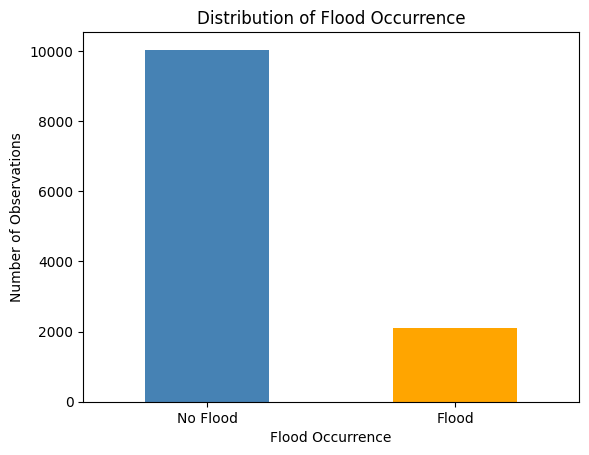

In [14]:
#Data visualization

import matplotlib.pyplot as plt

flood_dataset['Flood'].value_counts().sort_index().plot(
    kind='bar',
    color=['steelblue', 'orange']
)

plt.title('Distribution of Flood Occurrence')
plt.xlabel('Flood Occurrence')
plt.ylabel('Number of Observations')
plt.xticks([0, 1], ['No Flood', 'Flood'], rotation=0)

plt.show()


In [15]:

flood_dataset[
    flood_dataset['Rainfall'].isnull()
]
#we will keep these three null and handle them in feature engineering
#Handle historical state boundaries

flood_dataset['Date'] = pd.to_datetime(
    {
        'year': flood_dataset['Year'],
        'month': flood_dataset['Month'],
        'day': 1
    }
)

#New state formation to remeove prior data formation of states
formation_dates = {
    'Chhattisgarh': '2000-12-01',
    'Jharkhand': '2000-12-01',
    'Telangana': '2014-07-01'
}
#removing rows

print("Before filtering:", flood_dataset.shape)

for state, formation_date in formation_dates.items():

    formation_date = pd.Timestamp(formation_date)

    invalid_rows = (
        (flood_dataset['State'] == state) &
        (flood_dataset['Date'] < formation_date)
    )

    print(state, "Rows removed:", invalid_rows.sum())

    flood_dataset = flood_dataset[
        ~invalid_rows
    ].copy()

flood_dataset = flood_dataset.reset_index(drop=True)

print("After filtering:", flood_dataset.shape)

flood_dataset.head()


Before filtering: (12144, 7)
Chhattisgarh Rows removed: 371
Jharkhand Rows removed: 371
Telangana Rows removed: 534
After filtering: (10868, 7)


,State,Year,Month,Rainfall,Flood_Count,Flood,Date
0,Andhra Pradesh,1970,1,0.50,0,0,1970-01-01
1,Andhra Pradesh,1970,2,11.95,0,0,1970-02-01
2,Andhra Pradesh,1970,3,12.60,0,0,1970-03-01
3,Andhra Pradesh,1970,4,15.50,0,0,1970-04-01
4,Andhra Pradesh,1970,5,85.85,0,0,1970-05-01


# Feature Engineering

In [16]:
#Rainfall	Current month's rainfall
#Rainfall_Lag1	Previous month's rainfall
#Rainfall_Lag2	Rainfall two months earlier
#Rainfall_3Month	Cumulative rainfall over three months
#Sort the dataset chronologically
flood_dataset = flood_dataset.sort_values(
    by=['State', 'Year', 'Month']
).reset_index(drop=True)

flood_dataset['Rainfall_Lag1'] = (
    flood_dataset.groupby('State')['Rainfall']
    .shift(1)
)
flood_dataset['Rainfall_Lag2'] = (
    flood_dataset.groupby('State')['Rainfall']
    .shift(2)
)

flood_dataset['Rainfall_3Month'] = (
    flood_dataset['Rainfall'] +
    flood_dataset['Rainfall_Lag1'] +
    flood_dataset['Rainfall_Lag2']
)
print("Dataset shape:", flood_dataset.shape)

print("\nMissing values:")
print(flood_dataset.isnull().sum())

display(flood_dataset.head(12))

Dataset shape: (10868, 10)

Missing values:
State               0
Year                0
Month               0
Rainfall            3
Flood_Count         0
Flood               0
Date                0
Rainfall_Lag1      25
Rainfall_Lag2      47
Rainfall_3Month    51
dtype: int64


,State,Year,Month,Rainfall,Flood_Count,Flood,Date,Rainfall_Lag1,Rainfall_Lag2,Rainfall_3Month
0,Andhra Pradesh,1970,1,0.50,0,0,1970-01-01,NaN,NaN,NaN
1,Andhra Pradesh,1970,2,11.95,0,0,1970-02-01,0.50,NaN,NaN
2,Andhra Pradesh,1970,3,12.60,0,0,1970-03-01,11.95,0.50,25.05
3,Andhra Pradesh,1970,4,15.50,0,0,1970-04-01,12.60,11.95,40.05
4,Andhra Pradesh,1970,5,85.85,0,0,1970-05-01,15.50,12.60,113.95
5,Andhra Pradesh,1970,6,115.85,0,0,1970-06-01,85.85,15.50,217.20
6,Andhra Pradesh,1970,7,145.00,0,0,1970-07-01,115.85,85.85,346.70
7,Andhra Pradesh,1970,8,222.40,1,1,1970-08-01,145.00,115.85,483.25
8,Andhra Pradesh,1970,9,132.25,0,0,1970-09-01,222.40,145.00,499.65
9,Andhra Pradesh,1970,10,145.60,0,0,1970-10-01,132.25,222.40,500.25


In [17]:
missing_percentage = (
    flood_dataset['Rainfall_3Month'].isnull().sum()
    / len(flood_dataset)
) * 100

print("Missing percentage:", missing_percentage)
#Because we have already calculated the lag features using the complete monthly timeline.
#Dropping rows before calculating lag features could have caused incorrect previous-month rainfall values.
print("Before:", flood_dataset.shape)

flood_dataset = flood_dataset.dropna(
    subset=[
        'Rainfall',
        'Rainfall_Lag1',
        'Rainfall_Lag2',
        'Rainfall_3Month'
    ]
).reset_index(drop=True)

print("After:", flood_dataset.shape)

print(flood_dataset.isnull().sum())


Missing percentage: 0.4692675745307324
Before: (10868, 10)
After: (10817, 10)
State              0
Year               0
Month              0
Rainfall           0
Flood_Count        0
Flood              0
Date               0
Rainfall_Lag1      0
Rainfall_Lag2      0
Rainfall_3Month    0
dtype: int64


In [18]:
#Rainfall_Anomaly	Difference from typical monthly rainfall
#Month_Sin	Seasonal information
#Month_Cos	Seasonal information
#Is_Monsoon	Whether the month belongs to monsoon season

#If we calculate typical rainfall using the entire dataset, including 2006–2015, we would use information from the test period while creating training features.
#let's calculate a fixed historical rainfall reference using observations from 1970–2000.
#We will use state_rainfall, our original state-level rainfall DataFrame, because it contains the complete rainfall timeline before we removed observations based on lag availability and state formation dates.

historical_rainfall = state_rainfall[
    state_rainfall['Year'] <= 2000
].copy()
#climatology refers to the long-term average rainfall for a particular location and month
rainfall_climatology = historical_rainfall.groupby(
    ['State', 'Month']
)['Rainfall'].mean().reset_index()

rainfall_climatology = rainfall_climatology.rename(
    columns={'Rainfall': 'Normal_Rainfall'}
)
print(rainfall_climatology.shape)
rainfall_climatology.head(12)


(264, 3)


,State,Month,Normal_Rainfall
0,Andhra Pradesh,1,7.069355
1,Andhra Pradesh,2,10.212903
2,Andhra Pradesh,3,9.290323
3,Andhra Pradesh,4,20.609677
4,Andhra Pradesh,5,60.954839
5,Andhra Pradesh,6,94.980645
6,Andhra Pradesh,7,137.191935
7,Andhra Pradesh,8,154.850000
8,Andhra Pradesh,9,153.361290
9,Andhra Pradesh,10,160.493548


In [19]:
#Merge typical rainfall into our dataset

flood_dataset = pd.merge(
    flood_dataset,
    rainfall_climatology,
    on=['State', 'Month'],
    how='left',
    validate='many_to_one'
)

flood_dataset['Rainfall_Anomaly'] = (
    flood_dataset['Rainfall'] -
    flood_dataset['Normal_Rainfall']
)

flood_dataset[
    ['State', 'Year', 'Month',
     'Rainfall', 'Normal_Rainfall',
     'Rainfall_Anomaly']
].head(12)

flood_dataset.head()


,State,Year,Month,Rainfall,Flood_Count,Flood,Date,Rainfall_Lag1,Rainfall_Lag2,Rainfall_3Month,Normal_Rainfall,Rainfall_Anomaly
0,Andhra Pradesh,1970,3,12.60,0,0,1970-03-01,11.95,0.50,25.05,9.290323,3.309677
1,Andhra Pradesh,1970,4,15.50,0,0,1970-04-01,12.60,11.95,40.05,20.609677,-5.109677
2,Andhra Pradesh,1970,5,85.85,0,0,1970-05-01,15.50,12.60,113.95,60.954839,24.895161
3,Andhra Pradesh,1970,6,115.85,0,0,1970-06-01,85.85,15.50,217.20,94.980645,20.869355
4,Andhra Pradesh,1970,7,145.00,0,0,1970-07-01,115.85,85.85,346.70,137.191935,7.808065


In [20]:
#Seasonal feature engineering

flood_dataset['Month_Sin'] = np.sin(
    2 * np.pi * flood_dataset['Month'] / 12
)

flood_dataset['Month_Cos'] = np.cos(
    2 * np.pi * flood_dataset['Month'] / 12
)

flood_dataset[
    ['Month', 'Month_Sin', 'Month_Cos']
].head(12)



,Month,Month_Sin,Month_Cos
0,3,1.000000e+00,6.123234e-17
1,4,8.660254e-01,-5.000000e-01
2,5,5.000000e-01,-8.660254e-01
3,6,1.224647e-16,-1.000000e+00
4,7,-5.000000e-01,-8.660254e-01
5,8,-8.660254e-01,-5.000000e-01
6,9,-1.000000e+00,-1.836970e-16
7,10,-8.660254e-01,5.000000e-01
8,11,-5.000000e-01,8.660254e-01
9,12,-2.449294e-16,1.000000e+00


In [21]:

#Create a monsoon indicator
#main southwest monsoon season in India is June through September
#This is called domain-based feature engineering because we are using geographical and meteorological knowledge to create a meaningful feature.
flood_dataset['Is_Monsoon'] = (
    flood_dataset['Month'].isin([6, 7, 8, 9])
).astype(int)

flood_dataset[
    ['Month', 'Is_Monsoon']
].head(12)

,Month,Is_Monsoon
0,3,0
1,4,0
2,5,0
3,6,1
4,7,1
5,8,1
6,9,1
7,10,0
8,11,0
9,12,0


In [22]:

print("Final dataset shape:", flood_dataset.shape)

print("\nMissing values:")
print(flood_dataset.isnull().sum())

print("\nColumns:")
print(flood_dataset.columns.tolist())

display(flood_dataset.head(12))


Final dataset shape: (10817, 15)

Missing values:
State               0
Year                0
Month               0
Rainfall            0
Flood_Count         0
Flood               0
Date                0
Rainfall_Lag1       0
Rainfall_Lag2       0
Rainfall_3Month     0
Normal_Rainfall     0
Rainfall_Anomaly    0
Month_Sin           0
Month_Cos           0
Is_Monsoon          0
dtype: int64

Columns:
['State', 'Year', 'Month', 'Rainfall', 'Flood_Count', 'Flood', 'Date', 'Rainfall_Lag1', 'Rainfall_Lag2', 'Rainfall_3Month', 'Normal_Rainfall', 'Rainfall_Anomaly', 'Month_Sin', 'Month_Cos', 'Is_Monsoon']


,State,Year,Month,Rainfall,Flood_Count,Flood,Date,Rainfall_Lag1,Rainfall_Lag2,Rainfall_3Month,Normal_Rainfall,Rainfall_Anomaly,Month_Sin,Month_Cos,Is_Monsoon
0,Andhra Pradesh,1970,3,12.60,0,0,1970-03-01,11.95,0.50,25.05,9.290323,3.309677,1.000000e+00,6.123234e-17,0
1,Andhra Pradesh,1970,4,15.50,0,0,1970-04-01,12.60,11.95,40.05,20.609677,-5.109677,8.660254e-01,-5.000000e-01,0
2,Andhra Pradesh,1970,5,85.85,0,0,1970-05-01,15.50,12.60,113.95,60.954839,24.895161,5.000000e-01,-8.660254e-01,0
3,Andhra Pradesh,1970,6,115.85,0,0,1970-06-01,85.85,15.50,217.20,94.980645,20.869355,1.224647e-16,-1.000000e+00,1
4,Andhra Pradesh,1970,7,145.00,0,0,1970-07-01,115.85,85.85,346.70,137.191935,7.808065,-5.000000e-01,-8.660254e-01,1
5,Andhra Pradesh,1970,8,222.40,1,1,1970-08-01,145.00,115.85,483.25,154.850000,67.550000,-8.660254e-01,-5.000000e-01,1
6,Andhra Pradesh,1970,9,132.25,0,0,1970-09-01,222.40,145.00,499.65,153.361290,-21.111290,-1.000000e+00,-1.836970e-16,1
7,Andhra Pradesh,1970,10,145.60,0,0,1970-10-01,132.25,222.40,500.25,160.493548,-14.893548,-8.660254e-01,5.000000e-01,0
8,Andhra Pradesh,1970,11,32.45,0,0,1970-11-01,145.60,132.25,310.30,95.140323,-62.690323,-5.000000e-01,8.660254e-01,0
9,Andhra Pradesh,1970,12,0.25,0,0,1970-12-01,32.45,145.60,178.30,22.809677,-22.559677,-2.449294e-16,1.000000e+00,0


# Model Training


In [23]:
features = [
    'State',
    'Rainfall',
    'Rainfall_Lag1',
    'Rainfall_Lag2',
    'Rainfall_3Month',
    'Rainfall_Anomaly',
    'Month_Sin',
    'Month_Cos',
    'Is_Monsoon'
]

target = 'Flood'
#We would be training on observations from 2010 and evaluating on observations from 1985
train_data = flood_dataset[
    flood_dataset['Year'] <= 2005
].copy()

test_data = flood_dataset[
    flood_dataset['Year'] >= 2006
].copy()

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)


X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

#Check class distribution separately
print("Training class distribution:")

print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")

print(y_test.value_counts(normalize=True) * 100)

#Telangana only has observations from 2014 onwards in our dataset. Therefore, it will appear in our testing dataset but not in our training dataset.
unseen_states = (
    set(X_test['State']) -
    set(X_train['State'])
)

print("States not present in training:",
      unseen_states)


Training shape: (8288, 15)
Testing shape: (2529, 15)
X_train: (8288, 9)
y_train: (8288,)
X_test: (2529, 9)
y_test: (2529,)
Training class distribution:
Flood
0    82.094595
1    17.905405
Name: proportion, dtype: float64

Testing class distribution:
Flood
0    75.721629
1    24.278371
Name: proportion, dtype: float64
States not present in training: {'Telangana'}


In [24]:
#Implement One-Hot Encoding

from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

train_states_encoded = encoder.fit_transform(
    X_train[['State']]
)

test_states_encoded = encoder.transform(
    X_test[['State']]
)

print("Encoded training shape:",
      train_states_encoded.shape)

print("Encoded testing shape:",
      test_states_encoded.shape)
print(encoder.get_feature_names_out(['State']))

Encoded training shape: (8288, 21)
Encoded testing shape: (2529, 21)
['State_Andhra Pradesh' 'State_Arunachal Pradesh' 'State_Assam'
 'State_Bihar' 'State_Chhattisgarh' 'State_Gujarat' 'State_Haryana'
 'State_Himachal Pradesh' 'State_Jammu and Kashmir' 'State_Jharkhand'
 'State_Karnataka' 'State_Kerala' 'State_Madhya Pradesh'
 'State_Maharashtra' 'State_Meghalaya' 'State_Odisha' 'State_Punjab'
 'State_Rajasthan' 'State_Tamil Nadu' 'State_Uttar Pradesh'
 'State_West Bengal']


In [25]:
# Standard Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rainfall_train_scaled = scaler.fit_transform(
    X_train[['Rainfall']]
)

rainfall_test_scaled = scaler.transform(
    X_test[['Rainfall']]
)

print("Training rainfall mean:", scaler.mean_)

print("Training rainfall standard deviation:",
      scaler.scale_)

print("\nFirst 5 original values:")
print(X_train['Rainfall'].head().values)

print("\nFirst 5 scaled values:")
print(rainfall_train_scaled[:5])


Training rainfall mean: [119.50686434]
Training rainfall standard deviation: [154.3419461]

First 5 original values:
[ 12.6   15.5   85.85 115.85 145.  ]

First 5 scaled values:
[[-0.69266241]
 [-0.67387296]
 [-0.21806687]
 [-0.02369326]
 [ 0.16517309]]


In [26]:
#Define the column groups

categorical_features = ['State']

numerical_features = [
    'Rainfall',
    'Rainfall_Lag1',
    'Rainfall_Lag2',
    'Rainfall_3Month',
    'Rainfall_Anomaly'
]

seasonal_features = [
    'Month_Sin',
    'Month_Cos',
    'Is_Monsoon'
]

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_features
        ),
        (
            'season',
            'passthrough',
            seasonal_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:",
      X_train_processed.shape)

print("Processed testing shape:",
      X_test_processed.shape)
print(preprocessor.get_feature_names_out())

Processed training shape: (8288, 29)
Processed testing shape: (2529, 29)
['num__Rainfall' 'num__Rainfall_Lag1' 'num__Rainfall_Lag2'
 'num__Rainfall_3Month' 'num__Rainfall_Anomaly'
 'cat__State_Andhra Pradesh' 'cat__State_Arunachal Pradesh'
 'cat__State_Assam' 'cat__State_Bihar' 'cat__State_Chhattisgarh'
 'cat__State_Gujarat' 'cat__State_Haryana' 'cat__State_Himachal Pradesh'
 'cat__State_Jammu and Kashmir' 'cat__State_Jharkhand'
 'cat__State_Karnataka' 'cat__State_Kerala' 'cat__State_Madhya Pradesh'
 'cat__State_Maharashtra' 'cat__State_Meghalaya' 'cat__State_Odisha'
 'cat__State_Punjab' 'cat__State_Rajasthan' 'cat__State_Tamil Nadu'
 'cat__State_Uttar Pradesh' 'cat__State_West Bengal' 'season__Month_Sin'
 'season__Month_Cos' 'season__Is_Monsoon']


In [27]:
#Train Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ('preprocessing', preprocessor),

    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)

print("Model trained successfully!")


y_pred_lr = lr_pipeline.predict(X_test)

y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]

print("Predictions:")
print(y_pred_lr[:10])

print("\nFlood probability scores:")
print(y_prob_lr[:10])



Model trained successfully!
Predictions:
[0 0 0 0 0 0 0 1 1 1]

Flood probability scores:
[0.07848988 0.06877828 0.10827551 0.15240476 0.27106475 0.46709557
 0.47664993 0.71308854 0.72003496 0.51403175]


In [28]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("Precision:", precision_score(y_test, y_pred_lr))

print("Recall:", recall_score(y_test, y_pred_lr))

print("F1 Score:", f1_score(y_test, y_pred_lr))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

print("Average Precision:",
      average_precision_score(y_test, y_prob_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))


Accuracy: 0.8327402135231317
Precision: 0.6335664335664336
Recall: 0.737785016286645
F1 Score: 0.6817155756207675
ROC-AUC: 0.8867606160859322
Average Precision: 0.7294330383905986

Confusion Matrix:
[[1653  262]
 [ 161  453]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.86      0.89      1915
           1       0.63      0.74      0.68       614

    accuracy                           0.83      2529
   macro avg       0.77      0.80      0.78      2529
weighted avg       0.84      0.83      0.84      2529



In [32]:
#second model: Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import fbeta_score

dt_pipeline = Pipeline([
    ('preprocessing', preprocessor),

    ('model', DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=20,
        class_weight='balanced',
        random_state=42
    ))
])

dt_pipeline.fit(X_train, y_train)

print("Decision Tree trained successfully!")

y_pred_dt = dt_pipeline.predict(X_test)

y_prob_dt = dt_pipeline.predict_proba(X_test)[:, 1]

print("Decision Tree Results")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))
print("Average Precision:",
      average_precision_score(y_test, y_prob_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("Logistic Regression F2:",
      fbeta_score(y_test, y_pred_lr, beta=2))

print("Decision Tree F2:",
      fbeta_score(y_test, y_pred_dt, beta=2))


Decision Tree trained successfully!
Decision Tree Results
Accuracy: 0.8149466192170819
Precision: 0.585480093676815
Recall: 0.8143322475570033
F1 Score: 0.6811989100817438
ROC-AUC: 0.8647098595861576
Average Precision: 0.6507709716488527

Confusion Matrix:
[[1561  354]
 [ 114  500]]
Logistic Regression F2: 0.7142857142857143
Decision Tree F2: 0.7552870090634441


In [34]:
#trying different threshold for logistic regression

train_subset = train_data[
    train_data['Year'] <= 2000
].copy()

val_data = train_data[
    train_data['Year'] >= 2001
].copy()

X_train_sub = train_subset[features]
y_train_sub = train_subset['Flood']

X_val = val_data[features]
y_val = val_data['Flood']

print("Training:", X_train_sub.shape)
print("Validation:", X_val.shape)


from sklearn.base import clone

lr_val_pipeline = clone(lr_pipeline)

lr_val_pipeline.fit(X_train_sub, y_train_sub)

val_prob_lr = lr_val_pipeline.predict_proba(
    X_val
)[:, 1]


Training: (7030, 9)
Validation: (1258, 9)


In [36]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    fbeta_score
)

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    val_pred = (
        val_prob_lr >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': round(threshold, 2),
        'Precision': precision_score(
            y_val, val_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, val_pred, zero_division=0
        ),
        'F1': f1_score(
            y_val, val_pred, zero_division=0
        ),
        'F2': fbeta_score(
            y_val, val_pred,
            beta=2,
            zero_division=0
        )
    })

threshold_df_lr = pd.DataFrame(threshold_results)


from sklearn.metrics import accuracy_score, confusion_matrix

accuracy_values = []
fp_values = []
fn_values = []

for threshold in threshold_df_lr['Threshold']:

    predictions = (
        val_prob_lr >= threshold
    ).astype(int)

    accuracy_values.append(
        accuracy_score(y_val, predictions)
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    fp_values.append(fp)
    fn_values.append(fn)

threshold_df_lr['Accuracy'] = accuracy_values
threshold_df_lr['FP'] = fp_values
threshold_df_lr['FN'] = fn_values

display(
    threshold_df_lr[
        ['Threshold', 'Accuracy', 'Precision',
         'Recall', 'F1', 'F2', 'FP', 'FN']
    ].round(4)
)



,Threshold,Accuracy,Precision,Recall,F1,F2,FP,FN
0,0.10,0.4324,0.2645,0.9808,0.4167,0.6362,709,5
1,0.15,0.5580,0.3159,0.9769,0.4774,0.6887,550,6
2,0.20,0.6502,0.3673,0.9577,0.5309,0.7247,429,11
3,0.25,0.7043,0.4051,0.9192,0.5624,0.7331,351,21
4,0.30,0.7448,0.4426,0.9038,0.5942,0.7479,296,25
5,0.35,0.7774,0.4792,0.8846,0.6216,0.7566,250,30
6,0.40,0.8037,0.5154,0.8346,0.6373,0.7426,204,43
7,0.45,0.8331,0.5665,0.8192,0.6698,0.7521,163,47
8,0.50,0.8498,0.6060,0.7808,0.6824,0.7382,132,57
9,0.55,0.8561,0.6287,0.7423,0.6808,0.7164,114,67


In [38]:
#selected threshold 0.45

selected_threshold_lr = 0.45

y_pred_lr_tuned = (
    y_prob_lr >= selected_threshold_lr
).astype(int)

print("Tuned Logistic Regression Results")

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr_tuned))

print("Precision:",
      precision_score(y_test, y_pred_lr_tuned))

print("Recall:",
      recall_score(y_test, y_pred_lr_tuned))

print("F1:",
      f1_score(y_test, y_pred_lr_tuned))

print("F2:",
      fbeta_score(
          y_test, y_pred_lr_tuned, beta=2
      ))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr_tuned))


Tuned Logistic Regression Results
Accuracy: 0.8264136022143139
Precision: 0.6123234916559692
Recall: 0.7768729641693811
F1: 0.6848528356066045
F2: 0.7372488408037094

Confusion Matrix:
[[1613  302]
 [ 137  477]]


In [41]:
#Train Gradient Boosting

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gb_pipeline = Pipeline([
    ('preprocessing', preprocessor),

    ('model', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_pipeline.fit(X_train, y_train)

print("Gradient Boosting trained successfully!")

y_pred_gb = gb_pipeline.predict(X_test)
y_prob_gb = gb_pipeline.predict_proba(X_test)[:, 1]

print("Gradient Boosting Results")

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1:", f1_score(y_test, y_pred_gb))
print("F2:", fbeta_score(y_test, y_pred_gb, beta=2))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))
print("Average Precision:",
      average_precision_score(y_test, y_prob_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))


Gradient Boosting trained successfully!
Gradient Boosting Results
Accuracy: 0.8256227758007118
Precision: 0.7613293051359517
Recall: 0.41042345276872966
F1: 0.5333333333333333
F2: 0.4520990312163617
ROC-AUC: 0.883151189392844
Average Precision: 0.7327795684077524

Confusion Matrix:
[[1836   79]
 [ 362  252]]


In [43]:
#Hyperparameter Tuning
#Threshold

from sklearn.base import clone

gb_val_pipeline = clone(gb_pipeline)

gb_val_pipeline.fit(X_train_sub, y_train_sub)

val_prob_gb = gb_val_pipeline.predict_proba(
    X_val
)[:, 1]

print("Validation probabilities generated!")

gb_threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    val_pred = (
        val_prob_gb >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=[0, 1]
    ).ravel()

    gb_threshold_results.append({
        'Threshold': round(threshold, 2),
        'Accuracy': accuracy_score(y_val, val_pred),
        'Precision': precision_score(
            y_val, val_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, val_pred, zero_division=0
        ),
        'F1': f1_score(
            y_val, val_pred, zero_division=0
        ),
        'F2': fbeta_score(
            y_val, val_pred, beta=2, zero_division=0
        ),
        'FP': fp,
        'FN': fn
    })

gb_threshold_df = pd.DataFrame(gb_threshold_results)

display(gb_threshold_df.round(4))


Validation probabilities generated!


,Threshold,Accuracy,Precision,Recall,F1,F2,FP,FN
0,0.10,0.7949,0.5021,0.9000,0.6446,0.7769,232,26
1,0.15,0.8243,0.5481,0.8538,0.6677,0.7682,183,38
2,0.20,0.8394,0.5806,0.8038,0.6742,0.7464,151,51
3,0.25,0.8537,0.6226,0.7423,0.6772,0.7148,117,67
4,0.30,0.8553,0.6444,0.6692,0.6566,0.6641,96,86
5,0.35,0.8561,0.6639,0.6154,0.6387,0.6245,81,100
6,0.40,0.8553,0.6741,0.5808,0.6240,0.5973,73,109
7,0.45,0.8529,0.6904,0.5231,0.5952,0.5497,61,124
8,0.50,0.8410,0.7206,0.3769,0.4949,0.4167,38,162
9,0.55,0.8339,0.7802,0.2731,0.4046,0.3139,20,189


In [44]:

eligible_gb = gb_threshold_df[
    (gb_threshold_df['Recall'] >= 0.80) &
    (gb_threshold_df['Precision'] >= 0.55) &
    (gb_threshold_df['Accuracy'] >= 0.80)
]

if eligible_gb.empty:
    print("No threshold meets all three requirements.")
    print("\nHighest validation F2:")
    display(gb_threshold_df.nlargest(3, 'F2'))
else:
    best_gb = eligible_gb.loc[
        eligible_gb['F2'].idxmax()
    ]

    print("Selected threshold:", best_gb['Threshold'])
    print("Validation F2:", best_gb['F2'])
    print("Validation Recall:", best_gb['Recall'])
    print("Validation Accuracy:", best_gb['Accuracy'])


Selected threshold: 0.2
Validation F2: 0.7464285714285714
Validation Recall: 0.8038461538461539
Validation Accuracy: 0.8394276629570747


In [45]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

rf_pipeline = Pipeline([
    ('preprocessing', clone(preprocessor)),

    ('model', RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_val_pipeline = clone(rf_pipeline)

rf_val_pipeline.fit(X_train_sub, y_train_sub)

rf_val_prob = rf_val_pipeline.predict_proba(
    X_val
)[:, 1]

rf_val_pred = (
    rf_val_prob >= 0.5
).astype(int)

print("Random Forest Validation Results")

print("Accuracy:",
      accuracy_score(y_val, rf_val_pred))

print("Precision:",
      precision_score(y_val, rf_val_pred))

print("Recall:",
      recall_score(y_val, rf_val_pred))

print("F1:",
      f1_score(y_val, rf_val_pred))

print("F2:",
      fbeta_score(y_val, rf_val_pred, beta=2))

print("ROC-AUC:",
      roc_auc_score(y_val, rf_val_prob))

print("Average Precision:",
      average_precision_score(y_val, rf_val_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_val_pred))


Random Forest Validation Results
Accuracy: 0.8418124006359301
Precision: 0.5868945868945868
Recall: 0.7923076923076923
F1: 0.67430441898527
F2: 0.7404744787922358
ROC-AUC: 0.8947741637120394
Average Precision: 0.6736663597103476

Confusion Matrix:
[[853 145]
 [ 54 206]]


In [48]:
#model comparison on validation set

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score,
    average_precision_score
)
from sklearn.base import clone

# Decision Tree validation model
dt_val_pipeline = clone(dt_pipeline)
dt_val_pipeline.fit(X_train_sub, y_train_sub)

val_prob_dt = dt_val_pipeline.predict_proba(X_val)[:, 1]

models_val = {
    'Logistic Regression': (val_prob_lr, 0.45),
    'Decision Tree': (val_prob_dt, 0.50),
    'Gradient Boosting': (val_prob_gb, 0.20),
    'Random Forest': (rf_val_prob, 0.50)
}

results = []

for name, (prob, threshold) in models_val.items():

    pred = (prob >= threshold).astype(int)

    results.append({
        'Model': name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_val, pred),
        'Precision': precision_score(y_val, pred),
        'Recall': recall_score(y_val, pred),
        'F1': f1_score(y_val, pred),
        'F2': fbeta_score(y_val, pred, beta=2),
        'ROC-AUC': roc_auc_score(y_val, prob),
        'Avg Precision': average_precision_score(y_val, prob)
    })

final_validation_comparison = pd.DataFrame(results)

display(
    final_validation_comparison
    .sort_values('F2', ascending=False)
    .round(4)
)


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Avg Precision
0,Logistic Regression,0.45,0.8331,0.5665,0.8192,0.6698,0.7521,0.8936,0.6872
1,Decision Tree,0.50,0.8140,0.5320,0.8308,0.6486,0.7469,0.8543,0.5882
2,Gradient Boosting,0.20,0.8394,0.5806,0.8038,0.6742,0.7464,0.8958,0.6778
3,Random Forest,0.50,0.8418,0.5869,0.7923,0.6743,0.7405,0.8948,0.6737


In [50]:

# Train Random Forest on the full training dataset
rf_pipeline.fit(X_train, y_train)

print("Random Forest trained on full training data!")


Random Forest trained on full training data!


In [51]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score,
    average_precision_score, confusion_matrix
)
import pandas as pd

models_test = {
    'Logistic Regression': (lr_pipeline, 0.45),
    'Decision Tree': (dt_pipeline, 0.50),
    'Gradient Boosting': (gb_pipeline, 0.20),
    'Random Forest': (rf_pipeline, 0.50)
}

test_results = []

for name, (model, threshold) in models_test.items():

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    test_results.append({
        'Model': name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, zero_division=0
        ),
        'F1': f1_score(
            y_test, predictions, zero_division=0
        ),
        'F2': fbeta_score(
            y_test, predictions, beta=2, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_test, probabilities),
        'Avg Precision': average_precision_score(
            y_test, probabilities
        ),
        'FP': fp,
        'FN': fn
    })

final_test_comparison = pd.DataFrame(test_results)

display(
    final_test_comparison
    .sort_values('F2', ascending=False)
    .round(4)
)


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Avg Precision,FP,FN
1,Decision Tree,0.50,0.8149,0.5855,0.8143,0.6812,0.7553,0.8647,0.6508,354,114
0,Logistic Regression,0.45,0.8264,0.6123,0.7769,0.6849,0.7372,0.8868,0.7294,302,137
2,Gradient Boosting,0.20,0.8236,0.6126,0.7443,0.6721,0.7136,0.8832,0.7328,289,157
3,Random Forest,0.50,0.8217,0.6091,0.7410,0.6686,0.7103,0.8793,0.7133,292,159


In [52]:

state_results = test_data[['State', 'Flood']].copy()

state_results['Predicted'] = (
    lr_pipeline.predict_proba(X_test)[:, 1] >= 0.45
).astype(int)

state_metrics = []

for state, group in state_results.groupby('State'):

    actual = group['Flood']
    predicted = group['Predicted']

    state_metrics.append({
        'State': state,
        'Samples': len(group),
        'Actual Floods': actual.sum(),
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(
            actual, predicted, zero_division=0
        ),
        'Recall': recall_score(
            actual, predicted, zero_division=0
        ),
        'F2': fbeta_score(
            actual, predicted, beta=2, zero_division=0
        )
    })

state_comparison = pd.DataFrame(state_metrics)

display(
    state_comparison.sort_values('F2').round(4)
)


,State,Samples,Actual Floods,Accuracy,Precision,Recall,F2
14,Meghalaya,120,4,0.9167,0.2000,0.5000,0.3846
8,Jammu and Kashmir,113,27,0.7876,0.5517,0.5926,0.5839
18,Tamil Nadu,120,37,0.6667,0.4706,0.6486,0.6030
19,Telangana,16,3,0.8125,0.5000,0.6667,0.6250
0,Andhra Pradesh,120,27,0.7500,0.4651,0.7407,0.6623
6,Haryana,120,15,0.9167,0.6667,0.6667,0.6667
9,Jharkhand,120,14,0.8583,0.4400,0.7857,0.6790
16,Punjab,120,28,0.8333,0.6250,0.7143,0.6944
20,Uttar Pradesh,120,28,0.8000,0.5526,0.7500,0.7000
4,Chhattisgarh,120,17,0.8250,0.4375,0.8235,0.7000


In [53]:

from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from sklearn.metrics import fbeta_score
import pandas as pd
import numpy as np

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [2, 3],
    'min_samples_leaf': [5, 15]
}

gb_tuning_results = []

for params in ParameterGrid(param_grid):

    model = clone(gb_pipeline)

    model.set_params(
        model__n_estimators=params['n_estimators'],
        model__max_depth=params['max_depth'],
        model__min_samples_leaf=params['min_samples_leaf']
    )

    model.fit(X_train_sub, y_train_sub)

    probabilities = model.predict_proba(X_val)[:, 1]

    for threshold in [0.15, 0.20, 0.25]:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        accuracy = accuracy_score(y_val, predictions)
        precision = precision_score(
            y_val, predictions, zero_division=0
        )
        recall = recall_score(
            y_val, predictions, zero_division=0
        )
        f2 = fbeta_score(
            y_val, predictions, beta=2,
            zero_division=0
        )

        gb_tuning_results.append({
            **params,
            'Threshold': threshold,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F2': f2
        })

gb_tuning_df = pd.DataFrame(gb_tuning_results)

display(
    gb_tuning_df.sort_values(
        'F2', ascending=False
    ).round(4)
)

eligible_gb_tuned = gb_tuning_df[
    (gb_tuning_df['Accuracy'] >= 0.80) &
    (gb_tuning_df['Precision'] >= 0.55) &
    (gb_tuning_df['Recall'] >= 0.80)
]

if eligible_gb_tuned.empty:
    print("No configuration meets all requirements.")
else:
    best_gb_tuned = eligible_gb_tuned.loc[
        eligible_gb_tuned['F2'].idxmax()
    ]

    display(best_gb_tuned)


,max_depth,min_samples_leaf,n_estimators,Threshold,Accuracy,Precision,Recall,F2
12,3,5,100,0.15,0.8235,0.5470,0.8500,0.7652
3,2,5,200,0.15,0.8164,0.5349,0.8538,0.7629
18,3,15,100,0.15,0.8235,0.5473,0.8462,0.7628
9,2,15,200,0.15,0.8196,0.5403,0.8500,0.7626
21,3,15,200,0.15,0.8267,0.5530,0.8423,0.7625
15,3,5,200,0.15,0.8259,0.5519,0.8385,0.7596
0,2,5,100,0.15,0.8148,0.5325,0.8500,0.7595
6,2,15,100,0.15,0.8140,0.5312,0.8500,0.7589
10,2,15,200,0.20,0.8378,0.5769,0.8077,0.7479
16,3,5,200,0.20,0.8474,0.5983,0.7962,0.7468


,21
max_depth,3.000000
min_samples_leaf,15.000000
n_estimators,200.000000
Threshold,0.150000
Accuracy,0.826709
Precision,0.553030
Recall,0.842308
F2,0.762535


In [56]:

from sklearn.base import clone

gb_tuned_pipeline = clone(gb_pipeline)

gb_tuned_pipeline.set_params(
    model__n_estimators=200,
    model__learning_rate=0.05,
    model__max_depth=3,
    model__min_samples_leaf=15
)

gb_tuned_pipeline.fit(X_train, y_train)

print("Tuned Gradient Boosting trained successfully!")


gb_tuned_prob = gb_tuned_pipeline.predict_proba(X_test)[:, 1]

gb_tuned_pred = (gb_tuned_prob >= 0.15).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, gb_tuned_pred, labels=[0, 1]
).ravel()

gb_tuned_results = {
    'Model': 'Tuned Gradient Boosting',
    'Threshold': 0.15,
    'Accuracy': accuracy_score(y_test, gb_tuned_pred),
    'Precision': precision_score(
        y_test, gb_tuned_pred, zero_division=0
    ),
    'Recall': recall_score(
        y_test, gb_tuned_pred, zero_division=0
    ),
    'F1': f1_score(
        y_test, gb_tuned_pred, zero_division=0
    ),
    'F2': fbeta_score(
        y_test, gb_tuned_pred, beta=2, zero_division=0
    ),
    'ROC-AUC': roc_auc_score(y_test, gb_tuned_prob),
    'Avg Precision': average_precision_score(
        y_test, gb_tuned_prob
    ),
    'FP': fp,
    'FN': fn
}

display(pd.DataFrame([gb_tuned_results]).round(4))



Tuned Gradient Boosting trained successfully!


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Avg Precision,FP,FN
0,Tuned Gradient Boosting,0.15,0.8153,0.5887,0.7948,0.6764,0.7428,0.8891,0.7379,341,126


In [57]:

updated_comparison = pd.concat(
    [
        final_test_comparison,
        pd.DataFrame([gb_tuned_results])
    ],
    ignore_index=True
)

display(
    updated_comparison
    .sort_values('F2', ascending=False)
    .round(4)
)


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Avg Precision,FP,FN
1,Decision Tree,0.50,0.8149,0.5855,0.8143,0.6812,0.7553,0.8647,0.6508,354,114
4,Tuned Gradient Boosting,0.15,0.8153,0.5887,0.7948,0.6764,0.7428,0.8891,0.7379,341,126
0,Logistic Regression,0.45,0.8264,0.6123,0.7769,0.6849,0.7372,0.8868,0.7294,302,137
2,Gradient Boosting,0.20,0.8236,0.6126,0.7443,0.6721,0.7136,0.8832,0.7328,289,157
3,Random Forest,0.50,0.8217,0.6091,0.7410,0.6686,0.7103,0.8793,0.7133,292,159


# Model Output and Download

In [58]:

# Generate continuous flood risk scores
flood_risk_scores = lr_pipeline.predict_proba(X_test)[:, 1]

# Convert scores into binary predictions
flood_predictions = (flood_risk_scores >= 0.45).astype(int)

# Create Model 1 output dataset
model1_output = test_data[
    ['State', 'Year', 'Month', 'Rainfall']
].copy()

model1_output['Flood_Risk_Score'] = flood_risk_scores
model1_output['Flood_Prediction'] = flood_predictions

display(model1_output.head(10))


,State,Year,Month,Rainfall,Flood_Risk_Score,Flood_Prediction
430,Andhra Pradesh,2006,1,0.10,0.078490,0
431,Andhra Pradesh,2006,2,0.00,0.068778,0
432,Andhra Pradesh,2006,3,31.75,0.108276,0
433,Andhra Pradesh,2006,4,33.85,0.152405,0
434,Andhra Pradesh,2006,5,65.15,0.271065,0
435,Andhra Pradesh,2006,6,108.90,0.467096,1
436,Andhra Pradesh,2006,7,85.00,0.476650,1
437,Andhra Pradesh,2006,8,175.85,0.713089,1
438,Andhra Pradesh,2006,9,184.40,0.720035,1
439,Andhra Pradesh,2006,10,136.90,0.514032,1


In [59]:

import joblib

model1_artifact = {
    'model': lr_pipeline,
    'threshold': 0.45,
    'features': features,
    'model_name': 'Logistic Regression',
    'task': 'State-month flood occurrence classification'
}

joblib.dump(
    model1_artifact,
    'floodrelief_model1.pkl'
)

print("Model 1 saved successfully!")


Model 1 saved successfully!


In [60]:

saved_artifact = joblib.load('floodrelief_model1.pkl')

loaded_model = saved_artifact['model']
loaded_threshold = saved_artifact['threshold']

loaded_scores = loaded_model.predict_proba(X_test)[:, 1]
loaded_predictions = (
    loaded_scores >= loaded_threshold
).astype(int)

print(
    "Scores match:",
    np.allclose(loaded_scores, flood_risk_scores)
)

print(
    "Predictions match:",
    np.array_equal(loaded_predictions, flood_predictions)
)


Scores match: True
Predictions match: True


In [61]:

normal_rainfall_reference = (
    flood_dataset[
        ['State', 'Month', 'Normal_Rainfall']
    ]
    .drop_duplicates()
    .sort_values(['State', 'Month'])
    .reset_index(drop=True)
)

print("Reference table shape:", normal_rainfall_reference.shape)

display(normal_rainfall_reference.head(15))

duplicates = normal_rainfall_reference.duplicated(
    subset=['State', 'Month']
).sum()

missing = normal_rainfall_reference[
    'Normal_Rainfall'
].isna().sum()

print("Duplicate state-month entries:", duplicates)
print("Missing normal rainfall values:", missing)
print("Total reference entries:", len(normal_rainfall_reference))


Reference table shape: (264, 3)


,State,Month,Normal_Rainfall
0,Andhra Pradesh,1,7.069355
1,Andhra Pradesh,2,10.212903
2,Andhra Pradesh,3,9.290323
3,Andhra Pradesh,4,20.609677
4,Andhra Pradesh,5,60.954839
5,Andhra Pradesh,6,94.980645
6,Andhra Pradesh,7,137.191935
7,Andhra Pradesh,8,154.850000
8,Andhra Pradesh,9,153.361290
9,Andhra Pradesh,10,160.493548


Duplicate state-month entries: 0
Missing normal rainfall values: 0
Total reference entries: 264


In [63]:
#Create a reusable prediction function
import numpy as np
import pandas as pd

def predict_flood(
    state,
    year,
    month,
    rainfall,
    rainfall_lag1,
    rainfall_lag2
):
    # Find historical normal rainfall
    reference = normal_rainfall_reference[
        (normal_rainfall_reference['State'] == state) &
        (normal_rainfall_reference['Month'] == month)
    ]

    if reference.empty:
        raise ValueError("State-month reference not found")

    normal_rainfall = reference['Normal_Rainfall'].iloc[0]

    # Calculate engineered features
    rainfall_3month = (
        rainfall + rainfall_lag1 + rainfall_lag2
    )

    rainfall_anomaly = rainfall - normal_rainfall

    month_sin = np.sin(2 * np.pi * month / 12)
    month_cos = np.cos(2 * np.pi * month / 12)

    is_monsoon = int(month in [6, 7, 8, 9])

    # Prepare model input
    input_data = pd.DataFrame([{
        'State': state,
        'Rainfall': rainfall,
        'Rainfall_Lag1': rainfall_lag1,
        'Rainfall_Lag2': rainfall_lag2,
        'Rainfall_3Month': rainfall_3month,
        'Rainfall_Anomaly': rainfall_anomaly,
        'Month_Sin': month_sin,
        'Month_Cos': month_cos,
        'Is_Monsoon': is_monsoon
    }])

    # Generate predictions
    risk_score = lr_pipeline.predict_proba(
        input_data
    )[0, 1]

    flood_prediction = int(risk_score >= 0.45)

    return {
        'State': state,
        'Year': year,
        'Month': month,
        'Flood_Risk_Score': round(float(risk_score), 4),
        'Flood_Prediction': flood_prediction
    }


In [64]:

sample = test_data.iloc[0]

result = predict_flood(
    state=sample['State'],
    year=int(sample['Year']),
    month=int(sample['Month']),
    rainfall=float(sample['Rainfall']),
    rainfall_lag1=float(sample['Rainfall_Lag1']),
    rainfall_lag2=float(sample['Rainfall_Lag2'])
)

original_score = lr_pipeline.predict_proba(
    X_test.iloc[[0]]
)[0, 1]

print("Function output:", result)
print("Original model score:", round(float(original_score), 4))

print(
    "Scores match:",
    np.isclose(
        result['Flood_Risk_Score'],
        original_score,
        atol=0.00005
    )
)


Function output: {'State': 'Andhra Pradesh', 'Year': 2006, 'Month': 1, 'Flood_Risk_Score': 0.0785, 'Flood_Prediction': 0}
Original model score: 0.0785
Scores match: True


In [66]:

import joblib

model1_package = {
    'model': lr_pipeline,
    'threshold': 0.45,
    'normal_rainfall_reference': normal_rainfall_reference,
    'features': features,
    'model_name': 'Logistic Regression'
}

joblib.dump(
    model1_package,
    'floodrelief_model1_complete.pkl'
)

print("Complete Model 1 package saved!")


Complete Model 1 package saved!


In [67]:

loaded_package = joblib.load(
    'floodrelief_model1_complete.pkl'
)

print("Model:", loaded_package['model_name'])
print("Threshold:", loaded_package['threshold'])
print("Features:", loaded_package['features'])
print(
    "Rainfall reference entries:",
    len(loaded_package['normal_rainfall_reference'])
)


Model: Logistic Regression
Threshold: 0.45
Features: ['State', 'Rainfall', 'Rainfall_Lag1', 'Rainfall_Lag2', 'Rainfall_3Month', 'Rainfall_Anomaly', 'Month_Sin', 'Month_Cos', 'Is_Monsoon']
Rainfall reference entries: 264


In [68]:

from google.colab import files

files.download('floodrelief_model1_complete.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>